# Processamento de Sinais II — Lista 2
Solução usando OpenCV, NumPy e Matplotlib. Execute as células na ordem.

In [12]:
from pathlib import Path
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt

HERE = Path.cwd()
REPO = HERE if (HERE / 'data').exists() else HERE.parent
DATA = REPO / 'data' / 'dataset'

# O dataset já está disponível na pasta data/dataset do repositório.
def ler(nome, cinza=False):
    modo = cv2.IMREAD_GRAYSCALE if cinza else cv2.IMREAD_COLOR
    imagem = cv2.imread(str(DATA / nome), modo)
    if imagem is None: raise FileNotFoundError(nome)
    return imagem

def mostrar(imagens, colunas=4, tamanho=(4, 4)):
    linhas = int(np.ceil(len(imagens) / colunas))
    fig, axs = plt.subplots(linhas, colunas, figsize=(tamanho[0] * colunas, tamanho[1] * linhas), squeeze=False)
    axs = axs.ravel()
    for ax, (titulo, imagem) in zip(axs, imagens):
        if imagem.ndim == 3: imagem = cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)
        ax.imshow(imagem, cmap='gray')
        ax.set_title(titulo); ax.axis('off')
    for ax in axs[len(imagens):]: ax.axis('off')
    plt.tight_layout(); plt.show()

def disco(raio):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * raio + 1, 2 * raio + 1))

lena = ler('lena2.tif', True)
coins = ler('coins.jpg', True)
text = ler('text.tif', True)

## 15) Binarize a imagem Coins de modo a obter uma máscara binária para as moedas. Em seguida, aplique uma erosão usando um disco como elemento estruturante. Exiba as imagens e indique qual é o tamanho do disco que separa todas as moedas.

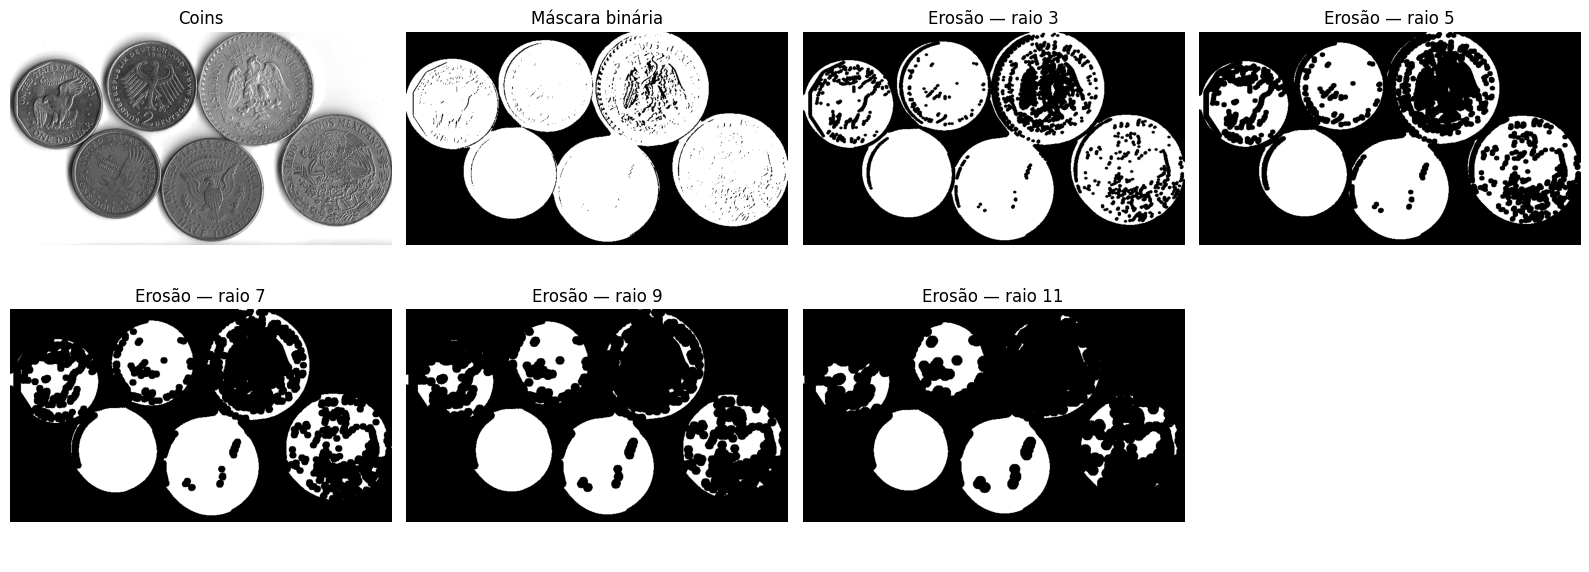

In [13]:
coins_suave = cv2.GaussianBlur(coins, (3, 3), 0)
_, moedas = cv2.threshold(coins_suave, 160, 255, cv2.THRESH_BINARY_INV)
erosoes = []
for raio in [3, 5, 7, 9, 11]:
    erosoes.append((f'Erosão — raio {raio}', cv2.erode(moedas, disco(raio))))
mostrar([('Coins', coins), ('Máscara binária', moedas)] + erosoes, colunas=4, tamanho=(4, 3))

O desfoque 3x3 e o limiar invertido em 160 deixam as moedas brancas sobre o fundo preto. O raio 3 ainda une um par; o menor disco testado que separa as seis tem raio 5 (11 pixels de diâmetro).

## 16) Usando a imagem Coins e um elemento estruturante disco, mostre que a erosão e a dilatação são operações duais, mas não possuem relações de inversão.

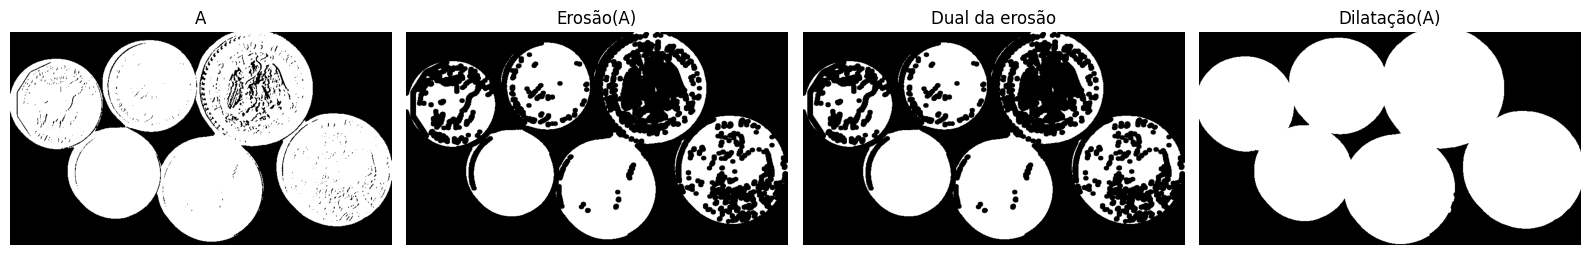

In [14]:
objeto = moedas > 0
complemento = np.uint8(~objeto) * 255
kernel = disco(5)
erosao = cv2.erode(np.uint8(objeto) * 255, kernel)
dual_da_erosao = cv2.bitwise_not(cv2.dilate(complemento, kernel))
dilatacao = cv2.dilate(np.uint8(objeto) * 255, kernel)
mostrar([('A', objeto), ('Erosão(A)', erosao), ('Dual da erosão', dual_da_erosao), ('Dilatação(A)', dilatacao)], colunas=4)

A erosão de A é igual ao complemento da dilatação do complemento de A, como mostram as duas imagens centrais. Porém, aplicar dilatação depois de erosão não recupera exatamente a imagem original: bordas removidas não podem ser reconstruídas dessa forma.

## 17) Usando a imagem Bintest e um elemento estruturante quadrado de tamanho similar ao menor quadrado, aplique abertura, fechamento e abertura seguida de fechamento.

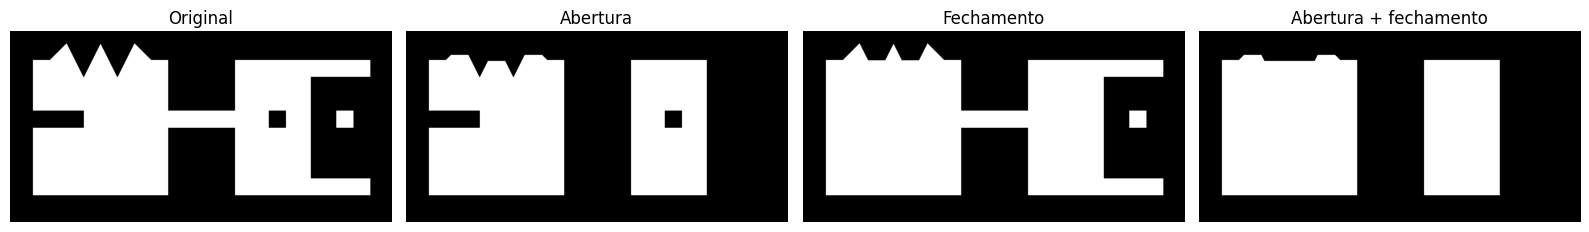

In [15]:
bintest = ler('bintest.png', True)
_, bintest = cv2.threshold(bintest, 127, 255, cv2.THRESH_BINARY)
quadrado = np.ones((55, 55), np.uint8)
abertura = cv2.morphologyEx(bintest, cv2.MORPH_OPEN, quadrado)
fechamento = cv2.morphologyEx(bintest, cv2.MORPH_CLOSE, quadrado)
abertura_fechamento = cv2.morphologyEx(abertura, cv2.MORPH_CLOSE, quadrado)
mostrar([('Original', bintest), ('Abertura', abertura), ('Fechamento', fechamento), ('Abertura + fechamento', abertura_fechamento)], colunas=4)

O elemento 55x55 tem lado próximo ao menor quadrado visível. A abertura remove o quadrado branco pequeno e o fechamento preenche o quadrado preto interno. Na sequência, o fechamento é aplicado depois da abertura.

## 18) Filtre a Lena gray usando filtro gaussiano bidimensional (σ = 3), filtragem separável, FFT e box filtering com imagem integral. Compare resultados e tempos.

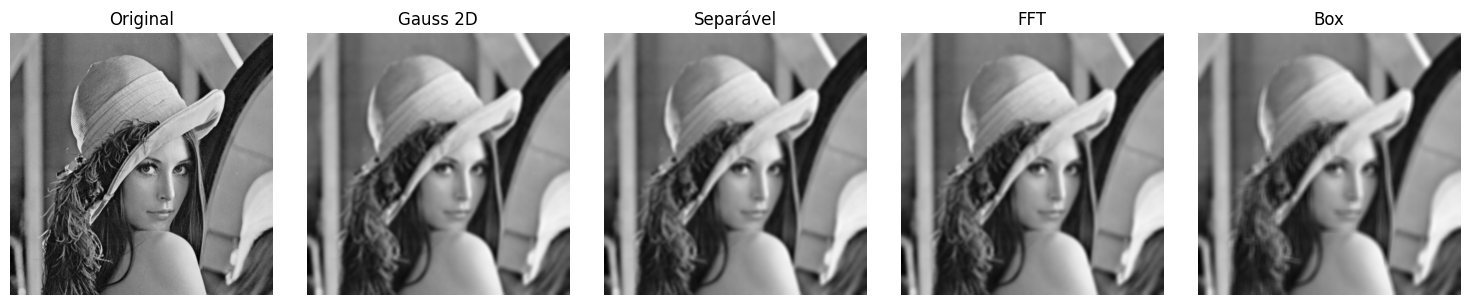

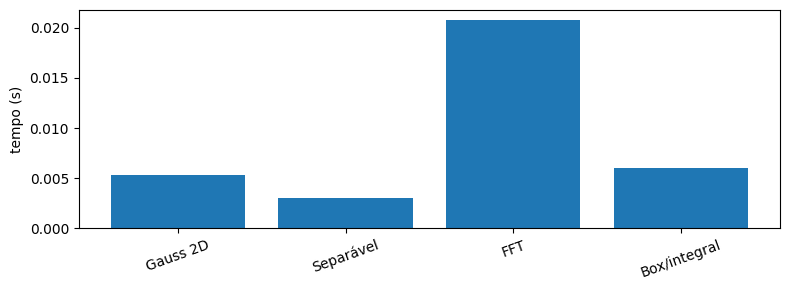

In [16]:
lena_float = lena.astype(np.float32)
kernel1d = cv2.getGaussianKernel(11, 3)
kernel2d = kernel1d @ kernel1d.T
tempos = {}

inicio = time.perf_counter(); gauss2d = cv2.filter2D(lena_float, -1, kernel2d); tempos['Gauss 2D'] = time.perf_counter() - inicio
inicio = time.perf_counter(); separavel = cv2.sepFilter2D(lena_float, -1, kernel1d, kernel1d); tempos['Separável'] = time.perf_counter() - inicio

inicio = time.perf_counter()
lena_pad = cv2.copyMakeBorder(lena_float, 5, 5, 5, 5, cv2.BORDER_REFLECT_101)
kernel_pad = np.zeros_like(lena_pad)
kernel_pad[:11, :11] = kernel2d
kernel_pad = np.roll(kernel_pad, (-5, -5), axis=(0, 1))
F = cv2.dft(lena_pad, flags=cv2.DFT_COMPLEX_OUTPUT)
K = cv2.dft(kernel_pad, flags=cv2.DFT_COMPLEX_OUTPUT)
fft_pad = cv2.idft(cv2.mulSpectrums(F, K, 0), flags=cv2.DFT_SCALE | cv2.DFT_REAL_OUTPUT)
fft_result = fft_pad[5:-5, 5:-5]
tempos['FFT'] = time.perf_counter() - inicio

inicio = time.perf_counter()
lena_pad = cv2.copyMakeBorder(lena_float, 5, 5, 5, 5, cv2.BORDER_REFLECT_101)
integral = cv2.integral(lena_pad)
box = (integral[11:, 11:] - integral[:-11, 11:] - integral[11:, :-11] + integral[:-11, :-11]) / 121
tempos['Box/integral'] = time.perf_counter() - inicio
mostrar([('Original', lena), ('Gauss 2D', gauss2d), ('Separável', separavel), ('FFT', fft_result), ('Box', box)], colunas=5, tamanho=(3, 3))
plt.figure(figsize=(8, 3)); plt.bar(tempos.keys(), tempos.values()); plt.ylabel('tempo (s)'); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

A filtragem 2D, a separável e a FFT produzem resultados praticamente iguais; a extensão das bordas evita o efeito circular da FFT. O filtro box usa pesos iguais e por isso suaviza de outro modo. O tempo mostrado para ele inclui o cálculo da imagem integral; os tempos dependem do computador.

## 19) Aplique uma filtragem sharpening usando os kernels dos slides 33 e 35 na imagem Lena gray. Compare os resultados.

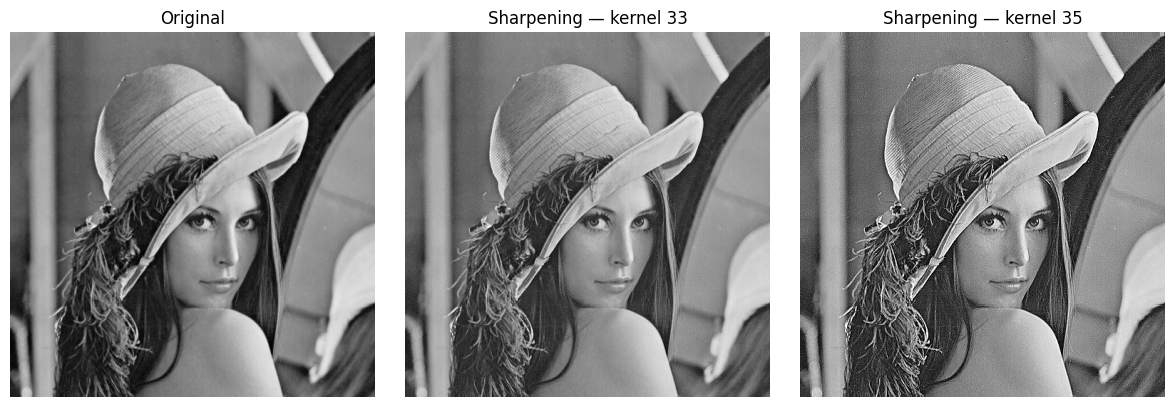

In [17]:
kernel_slide33 = 0.25 * np.array([[0, -1, 0], [-1, 8, -1], [0, -1, 0]], dtype=np.float32)
kernel_slide35 = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32)
sharp33 = cv2.filter2D(lena, -1, kernel_slide33)
sharp35 = cv2.filter2D(lena, -1, kernel_slide35)
mostrar([('Original', lena), ('Sharpening — kernel 33', sharp33), ('Sharpening — kernel 35', sharp35)], colunas=3)

O kernel do slide 33 usa escala 1/4 e realça as bordas de forma mais leve. O do slide 35 tem ganho maior nas altas frequências, então deixa os detalhes mais fortes e também pode realçar ruído.

## 20) Aplique os operadores de Prewitt, Sobel e Roberts na imagem da Lena sem binarizar. Compare os resultados e encontre limiares próximos.

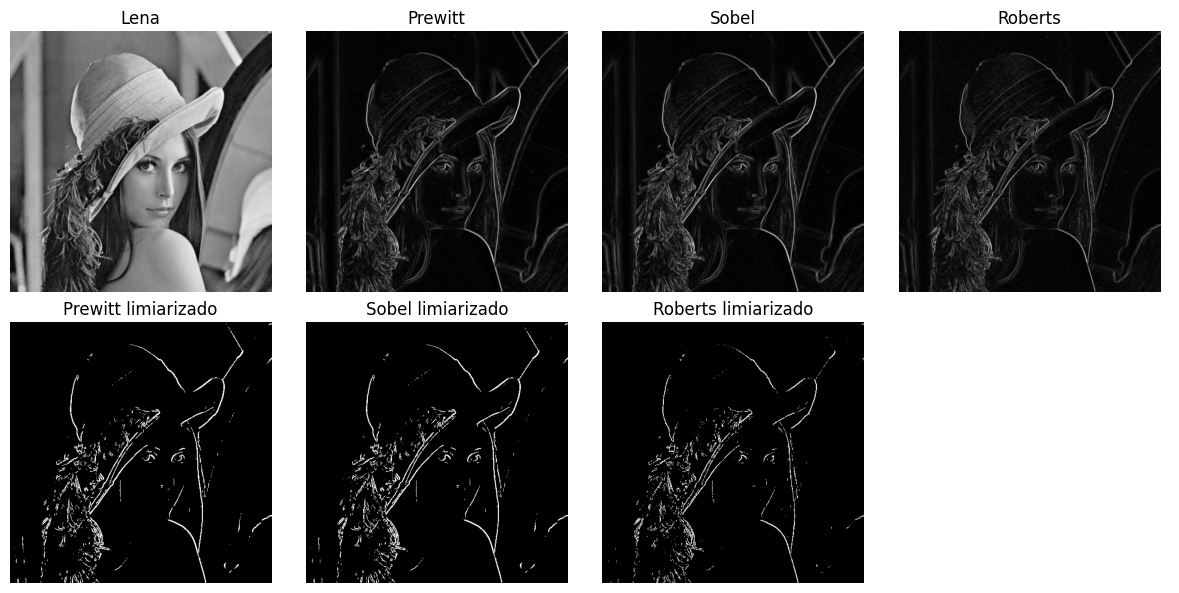

In [18]:
prewitt_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float32)
prewitt_y = prewitt_x.T
sobel_x = cv2.Sobel(lena, cv2.CV_32F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(lena, cv2.CV_32F, 0, 1, ksize=3)
prewitt = cv2.magnitude(cv2.filter2D(lena.astype(np.float32), -1, prewitt_x), cv2.filter2D(lena.astype(np.float32), -1, prewitt_y))
sobel = cv2.magnitude(sobel_x, sobel_y)
roberts_x = np.array([[1, 0], [0, -1]], dtype=np.float32)
roberts_y = np.array([[0, 1], [-1, 0]], dtype=np.float32)
roberts = cv2.magnitude(cv2.filter2D(lena.astype(np.float32), -1, roberts_x), cv2.filter2D(lena.astype(np.float32), -1, roberts_y))
prewitt8 = cv2.normalize(prewitt, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
sobel8 = cv2.normalize(sobel, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
roberts8 = cv2.normalize(roberts, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
_, p_limiar = cv2.threshold(prewitt8, 80, 255, cv2.THRESH_BINARY)
_, s_limiar = cv2.threshold(sobel8, 80, 255, cv2.THRESH_BINARY)
_, r_limiar = cv2.threshold(roberts8, 80, 255, cv2.THRESH_BINARY)
mostrar([('Lena', lena), ('Prewitt', prewitt8), ('Sobel', sobel8), ('Roberts', roberts8), ('Prewitt limiarizado', p_limiar), ('Sobel limiarizado', s_limiar), ('Roberts limiarizado', r_limiar)], colunas=4, tamanho=(3, 3))

Prewitt e Sobel usam uma vizinhança 3x3; Sobel dá peso maior ao pixel central e tende a ser mais suave. Roberts usa uma janela 2x2 e localiza bordas com mais sensibilidade a ruído. O limiar 80 foi mantido igual após a normalização para facilitar a comparação.

## 21) Aplique o detector de linhas de Hough na imagem Text e comente os resultados.

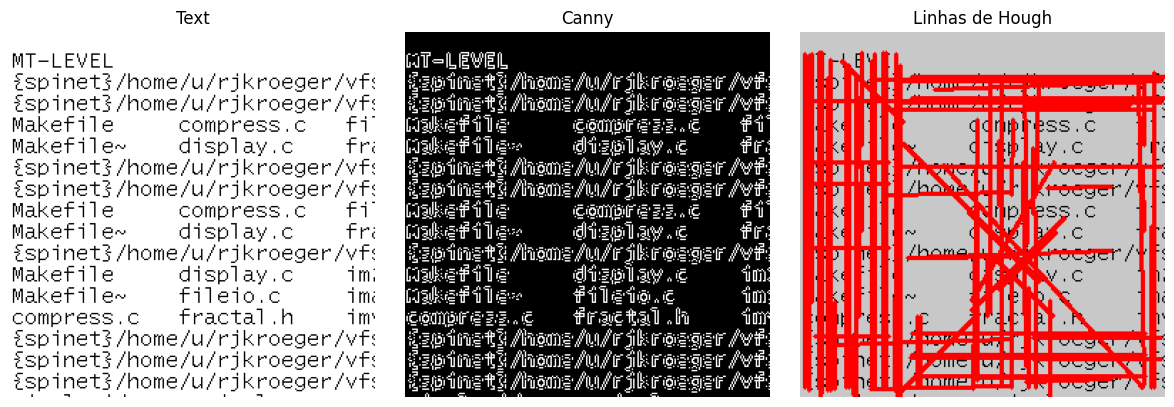

In [19]:
bordas_text = cv2.Canny(text, 50, 150, apertureSize=3)
linhas = cv2.HoughLinesP(bordas_text, 1, np.pi / 180, threshold=60, minLineLength=40, maxLineGap=10)
text_hough = cv2.cvtColor(text, cv2.COLOR_GRAY2BGR)
if linhas is not None:
    for linha in linhas[:, 0]:
        x1, y1, x2, y2 = linha
        cv2.line(text_hough, (x1, y1), (x2, y2), (0, 0, 255), 2)
mostrar([('Text', text), ('Canny', bordas_text), ('Linhas de Hough', text_hough)], colunas=3)

A transformada de Hough acumula evidências de pontos colineares. As linhas detectadas dependem do limiar, do comprimento mínimo e da distância máxima entre segmentos; textos com bordas quebradas podem gerar segmentos incompletos ou duplicados.

## 22) Aplique o detector de círculos de Hough na imagem Coins e comente os resultados.

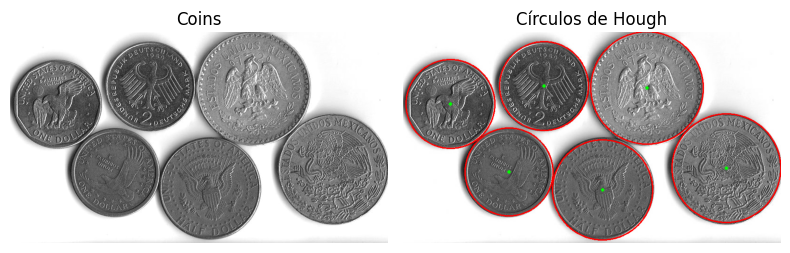

In [20]:
coins_suave = cv2.medianBlur(coins, 5)
circulos = cv2.HoughCircles(coins_suave, cv2.HOUGH_GRADIENT, dp=1, minDist=150, param1=100, param2=40, minRadius=70, maxRadius=120)
coins_hough = cv2.cvtColor(coins, cv2.COLOR_GRAY2BGR)
if circulos is not None:
    for x, y, raio in np.uint16(np.around(circulos[0])):
        cv2.circle(coins_hough, (x, y), raio, (0, 0, 255), 2)
        cv2.circle(coins_hough, (x, y), 2, (0, 255, 0), 3)
mostrar([('Coins', coins), ('Círculos de Hough', coins_hough)], colunas=2)

Com raios de 70 a 120 px, minDist 150 e param2 40, o detector marcou as seis moedas. Como as bordas não são círculos perfeitos, os contornos são aproximações.

## 23) Aplique os detectores Harris e FAST na imagem galinha1. Exiba os resultados e comente.

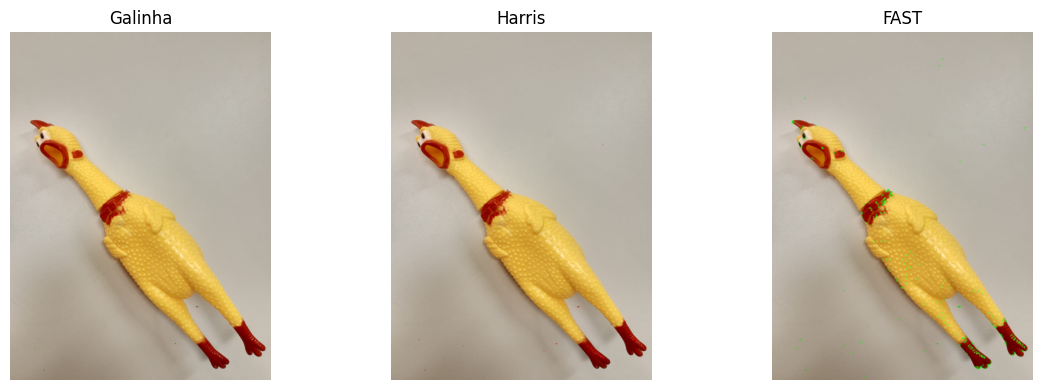

In [21]:
galinha1 = ler('galinha1.jpeg')
galinha1_gray = cv2.cvtColor(galinha1, cv2.COLOR_BGR2GRAY)
harris = cv2.cornerHarris(np.float32(galinha1_gray), 2, 3, 0.04)
harris_destaques = galinha1.copy()
harris_destaques[harris > 0.01 * harris.max()] = [0, 0, 255]
fast = cv2.FastFeatureDetector_create(threshold=20, nonmaxSuppression=True)
pontos_fast = fast.detect(galinha1_gray, None)
fast_destaques = cv2.drawKeypoints(galinha1, pontos_fast, None, color=(0, 255, 0))
mostrar([('Galinha', galinha1), ('Harris', harris_destaques), ('FAST', fast_destaques)], colunas=3)

Harris responde a variações de intensidade em duas direções e destaca cantos. FAST testa um círculo de pixels ao redor de cada ponto e é mais rápido, mas pode detectar muitos pontos dependendo do limiar.

## 24) Aplique SIFT nas imagens galinha1 e galinha2. Encontre e plote o casamento entre as keypoints. Repita o procedimento para SURF.

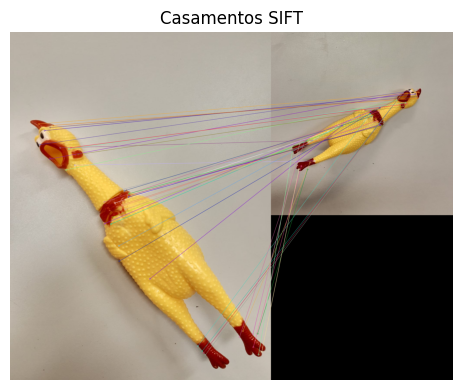

In [22]:
galinha2 = ler('galinha2.jpeg')
galinha2_gray = cv2.cvtColor(galinha2, cv2.COLOR_BGR2GRAY)
sift = cv2.SIFT_create()
pontos1, descritores1 = sift.detectAndCompute(galinha1_gray, None)
pontos2, descritores2 = sift.detectAndCompute(galinha2_gray, None)
buscador = cv2.BFMatcher()
pares = buscador.knnMatch(descritores1, descritores2, k=2)
bons = [m for m, n in pares if m.distance < 0.75 * n.distance]
casamentos_sift = cv2.drawMatches(galinha1, pontos1, galinha2, pontos2, bons, None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

surf_disponivel = hasattr(cv2, 'xfeatures2d') and hasattr(cv2.xfeatures2d, 'SURF_create')
casamentos_surf = None
if surf_disponivel:
    try:
        surf = cv2.xfeatures2d.SURF_create()
        p1, d1 = surf.detectAndCompute(galinha1_gray, None)
        p2, d2 = surf.detectAndCompute(galinha2_gray, None)
        if d1 is not None and d2 is not None:
            pares_surf = cv2.BFMatcher().knnMatch(d1, d2, k=2)
            bons_surf = [m for par in pares_surf if len(par) == 2 for m, n in [par] if m.distance < 0.75 * n.distance]
            casamentos_surf = cv2.drawMatches(galinha1, p1, galinha2, p2, bons_surf, None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    except (cv2.error, AttributeError):
        surf_disponivel = False
mostrar([('Casamentos SIFT', casamentos_sift)] + ([('Casamentos SURF', casamentos_surf)] if casamentos_surf is not None else []), colunas=1, tamanho=(8, 4))

SIFT cria descritores robustos a mudanças de escala e rotação, e o teste de razão de Lowe remove correspondências ambíguas. Esta instalação do OpenCV não disponibiliza SURF_create, então a célula mostra o resultado SIFT e só executa SURF quando o recurso está presente.

## 25) Escolha alguns frames da sequência de vídeo Chessboard e use-os para encontrar os parâmetros intrínsecos da câmera. Assuma que cada aresta do tabuleiro possui 58 mm.

In [23]:
pasta_chessboard = DATA / 'chessboard'
frames = sorted(list(pasta_chessboard.glob('*.jpg')) + list(pasta_chessboard.glob('*.png')) + list(pasta_chessboard.glob('*.tif'))) if pasta_chessboard.exists() else []
calibracao = None
if frames:
    tamanho_tabuleiro = (9, 6)
    pontos_3d = np.zeros((tamanho_tabuleiro[0] * tamanho_tabuleiro[1], 3), np.float32)
    pontos_3d[:, :2] = np.mgrid[0:tamanho_tabuleiro[0], 0:tamanho_tabuleiro[1]].T.reshape(-1, 2) * 58.0
    pontos_objeto, pontos_imagem = [], []
    for nome in frames:
        imagem = cv2.imread(str(nome), cv2.IMREAD_GRAYSCALE)
        achou, cantos = cv2.findChessboardCorners(imagem, tamanho_tabuleiro)
        if achou:
            pontos_objeto.append(pontos_3d)
            pontos_imagem.append(cantos)
    if pontos_imagem:
        calibracao = cv2.calibrateCamera(pontos_objeto, pontos_imagem, imagem.shape[::-1], None, None)
calibracao_disponivel = calibracao is not None

O dataset fornecido não contém a sequência de frames `Chessboard`, então `calibracao_disponivel` fica `False` nesta execução. O código está preparado para executar a calibração quando os frames forem colocados em `data/dataset/chessboard/`. A matriz de pontos usa espaçamento de 58 mm entre os cantos.